# Evaluation statistics for small numbers of trials

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/5_practice/01_evaluation_statistics.ipynb) &nbsp; Guide note: [guide-evaluation](https://www.matthewwnuk.com/guide-evaluation.html)

Robot evaluations are slow, so the number of trials is small, and small samples carry wide error bars.
This notebook works through the interval to report with a success rate, how many trials a comparison
needs, why pairing trials helps, and what happens if you peek at results and stop early.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from scipy import stats
from guide_utils import style
style.use(); z = stats.norm.ppf(0.975)

## Two intervals

The textbook interval is the observed rate plus or minus 1.96 standard errors. The Wilson interval solves
for the true rates consistent with the observation.

In [3]:
def textbook(k, n): p = k / n; h = z * np.sqrt(p * (1 - p) / n); return p - h, p + h
def wilson(k, n):
    p = k / n; centre = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n); return centre - h, centre + h
for k, n in ((7, 10), (14, 20), (70, 100), (20, 20), (0, 10)):
    a, b = textbook(k, n), wilson(k, n); print(f"{k:3d} of {n:3d}:  textbook {a[0]:6.1%} to {a[1]:6.1%}    Wilson {b[0]:6.1%} to {b[1]:6.1%}")

  7 of  10:  textbook  41.6% to  98.4%    Wilson  39.7% to  89.2%
 14 of  20:  textbook  49.9% to  90.1%    Wilson  48.1% to  85.5%
 70 of 100:  textbook  61.0% to  79.0%    Wilson  60.4% to  78.1%
 20 of  20:  textbook 100.0% to 100.0%    Wilson  83.9% to 100.0%
  0 of  10:  textbook   0.0% to   0.0%    Wilson   0.0% to  27.8%


At 20 out of 20 the textbook interval has zero width, which claims certainty from twenty trials.

## Does a "95%" interval contain the truth 95% of the time?

For a given true rate, every possible outcome of 20 trials has a known probability. Add up the
probability of the outcomes whose interval contains the truth.

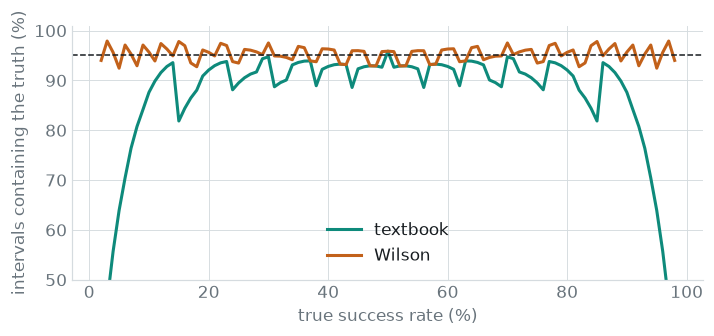

at a true rate of 90% with 20 trials: textbook 87.6%, Wilson 95.7%


In [4]:
def coverage(interval, n, p):
    k = np.arange(n + 1); lo, hi = interval(k, n); return stats.binom.pmf(k, n, p)[(lo <= p) & (p <= hi)].sum()
ps = np.linspace(0.02, 0.98, 97); plt.figure(figsize=(7.4, 3))
for name, f in (("textbook", textbook), ("Wilson", wilson)): plt.plot(ps * 100, [coverage(f, 20, p) * 100 for p in ps], label=name)
plt.axhline(95, color=style.INK, ls="--", lw=1); plt.ylim(50, 101); plt.xlabel("true success rate (%)"); plt.ylabel("intervals containing the truth (%)"); plt.legend(); plt.show()
print(f"at a true rate of 90% with 20 trials: textbook {coverage(textbook, 20, 0.9):.1%}, Wilson {coverage(wilson, 20, 0.9):.1%}")

## How many trials does a comparison need?

To detect a true difference with 80% power at the 5% level:

In [5]:
def trials_needed(p1, p2, power=0.8):
    pb = (p1 + p2) / 2; zb = stats.norm.ppf(power); return (z * np.sqrt(2 * pb * (1 - pb)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / (p2 - p1) ** 2
for gap in (0.05, 0.1, 0.2, 0.3): print(f"50% against {50 + gap * 100:.0f}%: {trials_needed(0.5, 0.5 + gap):5.0f} trials for each policy")

50% against 55%:  1565 trials for each policy
50% against 60%:   387 trials for each policy
50% against 70%:    93 trials for each policy
50% against 80%:    38 trials for each policy


Check it by simulation: run many pretend evaluations and count how often the better policy scores more.

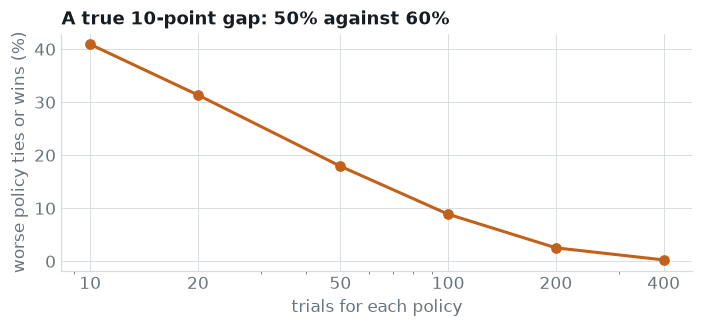

{10: '41%', 20: '31%', 50: '18%', 100: '9%', 200: '3%', 400: '0%'}


In [6]:
rng = np.random.default_rng(0); ns = [10, 20, 50, 100, 200, 400]; wrong = [np.mean(rng.binomial(n, 0.5, 20000) >= rng.binomial(n, 0.6, 20000)) * 100 for n in ns]
plt.figure(figsize=(7.4, 2.8)); plt.plot(ns, wrong, marker="o", color=style.ORANGE); plt.xscale("log"); plt.xticks(ns, ns); plt.xlabel("trials for each policy"); plt.ylabel("worse policy ties or wins (%)"); plt.title("A true 10-point gap: 50% against 60%"); plt.show()
print({n: f"{w:.0f}%" for n, w in zip(ns, wrong)})

## Pairing trials

Some starting conditions are hard for every policy and some are easy. If both policies are run from the
same conditions, that shared difficulty cancels. Simulate 40 conditions of varying difficulty, with
policy B a true 10 points better, and compare an unpaired test with McNemar's test, which looks only at
the conditions on which the two disagree.

In [7]:
def experiment(rng, n=40):
    difficulty = rng.beta(0.5, 0.5, n); pa = np.clip(difficulty - 0.05, 0, 1); pb = np.clip(difficulty + 0.05, 0, 1)
    u = rng.random(n); a, b = u < pa, u < pb                                           # same conditions, shared luck
    a2 = rng.random(n) < np.clip(rng.beta(0.5, 0.5, n) - 0.05, 0, 1)                    # A evaluated on different conditions
    unpaired = stats.fisher_exact([[b.sum(), n - b.sum()], [a2.sum(), n - a2.sum()]], alternative="greater")[1]
    only_b, only_a = (b & ~a).sum(), (a & ~b).sum(); paired = stats.binomtest(only_b, only_b + only_a, 0.5, alternative="greater").pvalue if only_b + only_a else 1.0
    return unpaired < 0.05, paired < 0.05
res = np.array([experiment(rng) for _ in range(3000)]); print(f"the 10-point improvement is detected {res[:, 0].mean():.0%} of the time unpaired, {res[:, 1].mean():.0%} of the time paired")

the 10-point improvement is detected 14% of the time unpaired, 29% of the time paired


## Peeking

Suppose two policies are identical. Test after every 10 trials and stop as soon as the difference looks
significant. How often does that declare a winner?

In [8]:
def peeks(rng, total=200, every=10):
    a, b = rng.random(total) < 0.6, rng.random(total) < 0.6
    for n in range(every, total + 1, every):
        if stats.fisher_exact([[a[:n].sum(), n - a[:n].sum()], [b[:n].sum(), n - b[:n].sum()]])[1] < 0.05: return True
    return False
fixed = np.mean([stats.fisher_exact([[x, 200 - x], [y, 200 - y]])[1] < 0.05 for x, y in zip(rng.binomial(200, 0.6, 2000), rng.binomial(200, 0.6, 2000))])
print(f"false winners with one test at the end: {fixed:.1%}"); print(f"false winners when peeking every 10 trials: {np.mean([peeks(rng) for _ in range(2000)]):.1%}")

false winners with one test at the end: 3.6%


false winners when peeking every 10 trials: 16.4%


Fix the number of trials before starting, or use a test designed for stopping early.

## Things to try

- Repeat the coverage plot for 100 trials. Does the textbook interval recover?
- In the pairing experiment, make the conditions equally hard (`difficulty = 0.5`). Does pairing still help?
- Compare twenty identical policies against a baseline at the 5% level. How many "win"?